# Data Analysis #

### This file (dyoldas_draft/data_analysis.ipynb) is only used to visualize and analyze the data, it is not a proper module of the main project structure. ###

### The steps here should provide detailed explanation to what is being automatically done in dyoldas_draft/jet_tagging/data.py file. ###

In [1]:
# Lets start by downloading necessary libaries...

import h5py
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

In [2]:
# Read, clean, and save data as pandas dataframes, also make a NDArray copy.

# !!! Initial Cleaning !!!
# Replace infs with nans and drop rows with nans
def clean_data(data: pd.DataFrame) -> pd.DataFrame:
    data = data.replace([np.inf, -np.inf], np.nan)
    data.dropna(inplace=True)
    return data

qcd_df = clean_data(pd.read_hdf("data/qcd_small.h5"))
top_df = clean_data(pd.read_hdf("data/top_small.h5"))
wz_df = clean_data(pd.read_hdf("data/wz_small.h5"))

qcd_np = qcd_df.to_numpy()
top_np = top_df.to_numpy()
wz_np = wz_df.to_numpy()

### Task 1: Binary Classification between QCD and Top jets ###

In [3]:
# Lets peek at the QCD and Top jet data

qcd_df.head()

,pt,eta,phi,mass,tau1,tau2,tau3,d12,d23,ECF2,ECF3
0,607.072967,-1.009798,-1.692294,74.279924,0.106777,0.053847,0.048443,71.625769,17.189248,0.069776,0.000578
1,617.878138,-1.652939,-2.824155,77.311970,0.063952,0.049932,0.034789,36.724516,11.378308,0.046499,0.000497
2,453.319866,-0.240723,-1.092266,89.176157,0.130441,0.062013,0.042345,50.477919,15.181665,0.081956,0.001697
3,544.399321,0.271492,-0.508073,72.242345,0.059550,0.039407,0.024691,24.216273,10.592004,0.045823,0.000552
4,498.415541,-1.968640,-2.578714,121.489030,0.157421,0.118271,0.106438,47.376547,28.395109,0.118631,0.004362


In [4]:
top_df.head()

,pt,eta,phi,mass,tau1,tau2,tau3,d12,d23,ECF2,ECF3
0,573.512896,0.001286,-1.439587,169.559158,0.258243,0.087235,0.031253,145.331607,33.307623,0.150575,0.004606
1,453.906445,0.148402,-0.015148,145.272721,0.267623,0.102800,0.066175,129.132864,27.523841,0.171669,0.007646
2,478.369848,-0.952453,1.408995,119.665687,0.135924,0.085038,0.046444,43.297613,23.269530,0.101354,0.003606
3,478.048060,1.861573,1.775839,168.655579,0.281357,0.142024,0.059981,109.025442,42.558432,0.172889,0.008726
4,505.042383,0.352444,1.669010,174.539199,0.296595,0.157693,0.104523,148.969734,51.627565,0.199092,0.010626


In [5]:
wz_df.head()

,pt,eta,phi,mass,tau1,tau2,tau3,d12,d23,ECF2,ECF3
0,509.569960,-0.010971,0.412726,74.449619,0.110025,0.075010,0.043799,46.578386,25.043906,0.080661,0.000889
1,908.238719,0.141990,-0.037208,105.411824,0.092030,0.057195,0.034095,79.972016,29.868654,0.063022,0.000467
2,715.397802,-0.332765,1.876226,69.131360,0.059496,0.046578,0.022350,40.628226,22.693048,0.040885,0.000255
3,485.802585,-1.615350,-1.755961,94.835553,0.171787,0.039508,0.026744,91.734220,10.754868,0.101506,0.001038
4,473.369069,2.230078,-0.083008,86.307155,0.170779,0.022420,0.021404,112.050288,3.939064,0.093596,0.000792


In [6]:
# Lets list all features, and check if they share same features (they should be)

print(list(qcd_df.keys()))
print("They share the same features:", list(qcd_df.keys())==list(top_df.keys()))

['pt', 'eta', 'phi', 'mass', 'tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3']
They share the same features: True


In [7]:
# Lets also check the shapes

print("QCD:", "Rows:", qcd_df.shape[0], "Columns:", qcd_df.shape[1])
print("Top:", "Rows:", top_df.shape[0], "Columns:", top_df.shape[1])
print("WZ:", "Rows:", wz_df.shape[0], "Columns:", wz_df.shape[1])

QCD: Rows: 500000 Columns: 11
Top: Rows: 300000 Columns: 11
WZ: Rows: 746865 Columns: 11


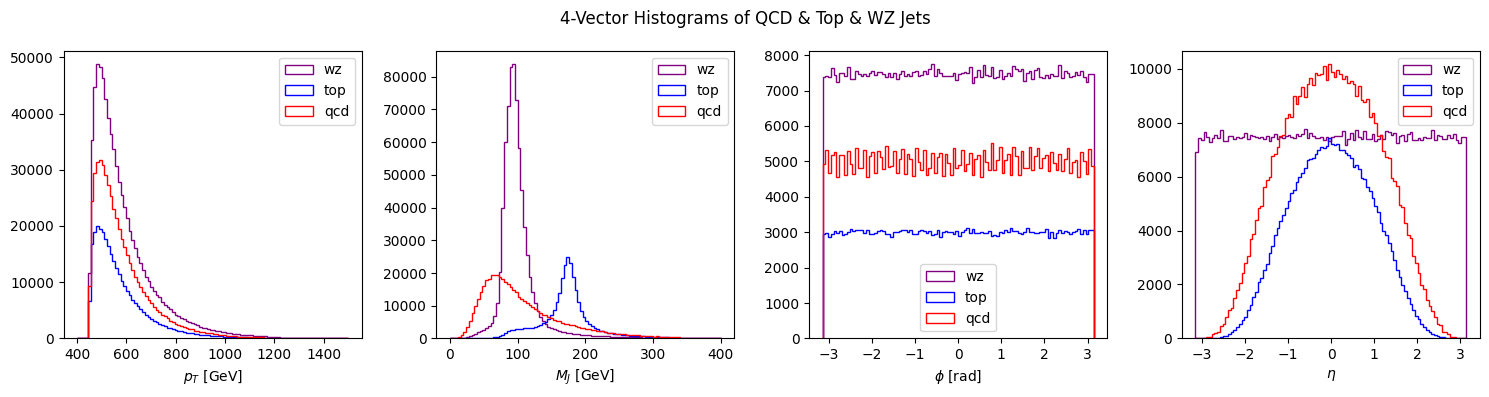

In [8]:
# 'pt', 'eta', 'phi', 'mass' are the 4-vector of the jets
# 'tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3' are extra substructe features which are crucial for distinguishing jets

# Lets plot these features...
fig, axes = plt.subplots(1, 4,figsize=(15, 4)) # 1 row, 4 plots
labels = ['qcd', 'top', 'wz']
colors = ['red', 'blue', 'purple']
n_bins = 100

axes[0].hist([qcd_df.pt, top_df.pt, wz_df.pt], bins=n_bins, range=[400,1500],histtype='step', color=colors, label=labels)
axes[0].legend()
axes[0].set_xlabel(r'$p_T$ [GeV]') # GeV in, (I thought ATLAS used MeV, CMS used GeV)

axes[1].hist([qcd_df.mass, top_df.mass, wz_df.mass], bins=n_bins, range=[0,400], histtype='step', color=colors, label=labels)
axes[1].legend()
axes[1].set_xlabel(r'$M_J$ [GeV]')

axes[2].hist([qcd_df.phi, top_df.phi, wz_df.phi], bins=n_bins, histtype='step', color=colors, label=labels)
axes[2].legend()
axes[2].set_xlabel(r'$\phi$ [rad]')

axes[3].hist([qcd_df.eta, top_df.eta, wz_df.phi], bins=n_bins, histtype='step', color=colors, label=labels)
axes[3].legend()
axes[3].set_xlabel(r'$\eta$')

fig.suptitle("4-Vector Histograms of QCD & Top & WZ Jets")  # Use suptitle for the figure

plt.tight_layout()
plt.show()

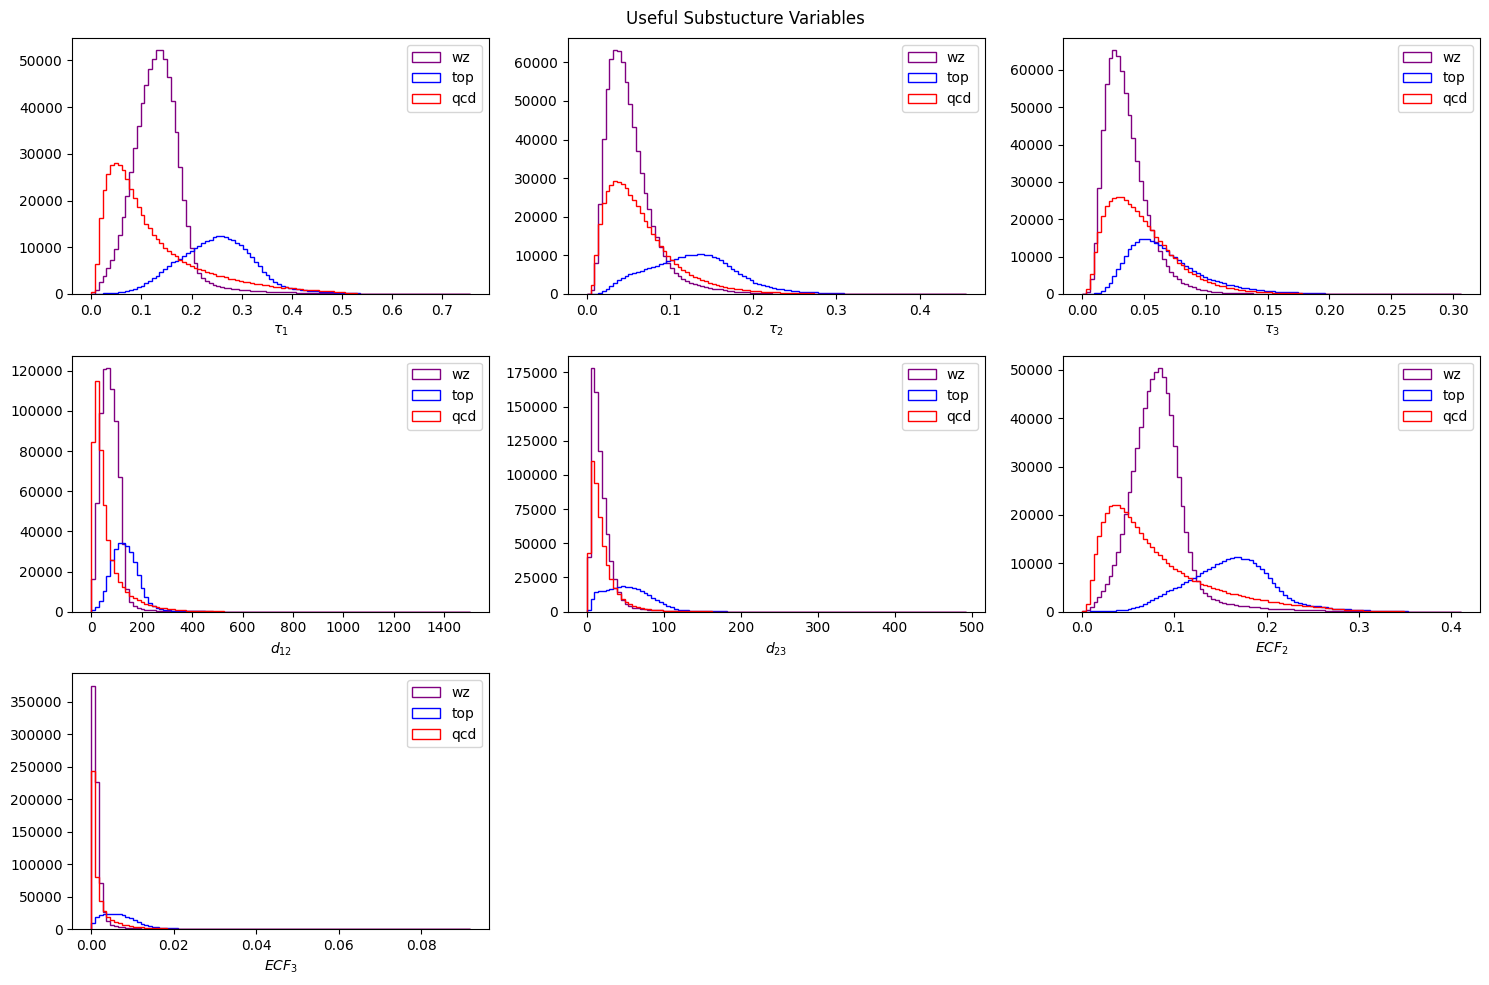

In [9]:
# more plots ...
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
labels = ['qcd', 'top', 'wz']
colors = ['red', 'blue', 'purple']
n_bins = 100

axes[0].hist([qcd_df.tau1, top_df.tau1, wz_df.tau1], bins=n_bins, histtype='step', color=colors, label=labels)
axes[0].legend()
axes[0].set_xlabel(r'$\tau_1$')

axes[1].hist([qcd_df.tau2, top_df.tau2, wz_df.tau2], bins=n_bins, histtype='step', color=colors, label=labels)
axes[1].legend()
axes[1].set_xlabel(r'$\tau_2$')

axes[2].hist([qcd_df.tau3, top_df.tau3, wz_df.tau3], bins=n_bins, histtype='step', color=colors, label=labels)
axes[2].legend()
axes[2].set_xlabel(r'$\tau_3$')

axes[3].hist([qcd_df.d12, top_df.d12, wz_df.d12], bins=n_bins, histtype='step', color=colors, label=labels)
axes[3].legend()
axes[3].set_xlabel(r'$d_{12}$')

axes[4].hist([qcd_df.d23, top_df.d23, wz_df.d23], bins=n_bins, histtype='step', color=colors, label=labels)
axes[4].legend()
axes[4].set_xlabel(r'$d_{23}$')

axes[5].hist([qcd_df.ECF2, top_df.ECF2, wz_df.ECF2], bins=n_bins, histtype='step', color=colors, label=labels)
axes[5].legend()
axes[5].set_xlabel(r'$ECF_2$')

axes[6].hist([qcd_df.ECF3, top_df.ECF3, wz_df.ECF3], bins=n_bins, histtype='step', color=colors, label=labels)
axes[6].legend()
axes[6].set_xlabel(r'$ECF_3$')

for ax in axes[7:]:
    ax.axis('off')

fig.suptitle("Useful Substucture Variables")

plt.tight_layout()
plt.show()

4-Vector distributions follow similar shape, but number of QCD data is higher than that of Top, lets analyze its consequences...

Lets assign the label 1 to QCD and 0 to Top jets for the sake of classification...

In [10]:
qcd_df['label'] = 0
qcd_df.head()

,pt,eta,phi,mass,tau1,tau2,tau3,d12,d23,ECF2,ECF3,label
0,607.072967,-1.009798,-1.692294,74.279924,0.106777,0.053847,0.048443,71.625769,17.189248,0.069776,0.000578,0
1,617.878138,-1.652939,-2.824155,77.311970,0.063952,0.049932,0.034789,36.724516,11.378308,0.046499,0.000497,0
2,453.319866,-0.240723,-1.092266,89.176157,0.130441,0.062013,0.042345,50.477919,15.181665,0.081956,0.001697,0
3,544.399321,0.271492,-0.508073,72.242345,0.059550,0.039407,0.024691,24.216273,10.592004,0.045823,0.000552,0
4,498.415541,-1.968640,-2.578714,121.489030,0.157421,0.118271,0.106438,47.376547,28.395109,0.118631,0.004362,0


In [11]:
top_df['label'] = 1
wz_df['label'] = 1

# Stack (concatenate) qcd_df and top_df
combined_df = pd.concat([qcd_df, top_df, wz_df], ignore_index=True)

# Shuffle rows with a fixed random seed (e.g., 42)
shuffled_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(shuffled_df.shape)


(1546865, 12)


In [12]:
shuffled_df.head()

,pt,eta,phi,mass,tau1,tau2,tau3,d12,d23,ECF2,ECF3,label
0,500.258556,-0.687807,1.452475,80.610125,0.153212,0.037310,0.035325,104.582940,7.663037,0.087803,0.000668,1
1,554.430031,-0.698239,-0.157283,94.626208,0.123131,0.041632,0.037156,52.636877,11.490017,0.074698,0.000870,1
2,543.012978,1.379919,2.499965,126.717186,0.180784,0.085174,0.057069,106.552561,34.725317,0.116464,0.003333,1
3,603.547684,-0.438944,0.081092,101.022647,0.063363,0.034130,0.021038,22.986118,8.490583,0.043091,0.000600,1
4,463.937509,-1.179105,-1.634616,85.837103,0.105316,0.047448,0.034958,31.314391,13.930593,0.070932,0.001109,1


Loss of random guess =  0.6931471824645996


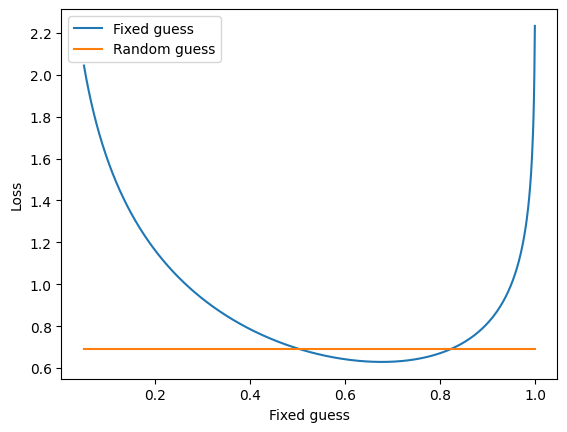

In [13]:
# First we define the general BCE loss function
def binary_crossentropy(true, pred, epsilon=1e-10):
    return -(true * np.log(pred + epsilon) + (1 - true) * np.log((1 - pred) + epsilon)).mean()

# Create a guess of 0.5 for all events
guess = 0.5 * np.ones_like(shuffled_df.label.values, dtype=np.float32)

# Calculate the loss using the true labels and the guess
loss = binary_crossentropy(shuffled_df.label.values, guess)
print("Loss of random guess = ", loss)

# Let's make random guesses between 0 and 1
guesses = np.arange(0.05, 1.0, 0.001)

# For each we calculate the loss
losses = [binary_crossentropy(shuffled_df.label.values, g) for g in guesses]

plt.plot(guesses, losses, label="Fixed guess")
plt.plot(guesses, loss * np.ones_like(guesses), label="Random guess")
plt.xlabel("Fixed guess")
plt.ylabel("Loss")
plt.legend()

Not good, there is a fixed guess around 0.6 that is better than the random guess. This is not machine learning...

Lets derive two weights, one for each class, that will result in the minimum of the blue curve falling at 0.5.
* The bias is caused by one class having more events than the other
* We can make the weight inversely proportional to the number of events in each class
* We also scale by (number of samples * 0.5)
    * This is because we want the sum of the weights to be equal to the number of samples

In [14]:
scale = len(shuffled_df) * 0.5
weight_0 = scale / np.sum(shuffled_df.label == 0)
weight_1 = scale / np.sum(shuffled_df.label == 1)

print('weight_qcd:', weight_0, 'weight_top/wz:', weight_1)

weight_qcd: 1.546865 weight_top/wz: 0.738808251302699


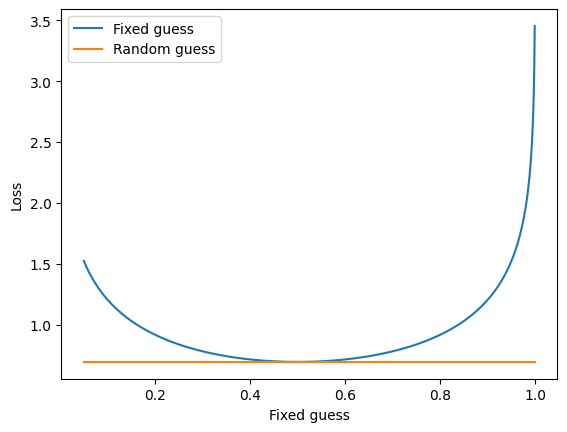

In [15]:
# It might be smart to convert the above loss function into a class, since the class-weights are fixed between subsequent calls.
# Lets do weighted binary cross entropy
def weighted_binary_crossentropy(true, pred, weight0, weight1, epsilon=1e-16):
    return -(
            true * np.log(pred + epsilon) * weight1
            + (1 - true) * np.log((1 - pred) + epsilon) * weight0
    ).mean()

guesses = np.arange(0.05, 1.0, 0.001)
losses = [
    weighted_binary_crossentropy(shuffled_df.label.values, g, weight_0, weight_1)
    for g in guesses
]
plt.plot(guesses, losses, label="Fixed guess")
plt.plot(guesses, loss * np.ones_like(losses), label="Random guess")
plt.xlabel("Fixed guess")
plt.ylabel("Loss")
plt.legend()
plt.show()

Amazing, that bias is eliminated, lets see how those weights will affect our plots...

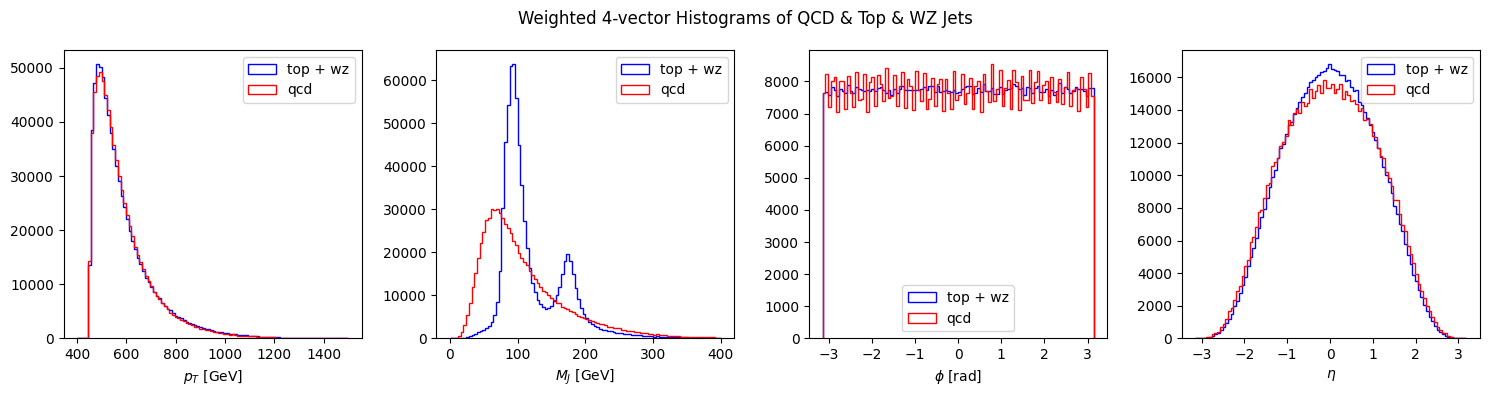

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
labels = ['qcd', 'top + wz']
colors = ['red', 'blue']
ranges = [[400,1500],[0,400],None,None]
n_bins = 100
weight_arrays = [np.full(len(qcd_df), weight_0), np.full((len(top_df)+len(wz_df)), weight_1)]
features = ['pt', 'mass', 'phi', 'eta']
xlabels = [r'$p_T$ [GeV]', r'$M_J$ [GeV]', r'$\phi$ [rad]', r'$\eta$']
signal_df = pd.concat([top_df, wz_df], axis=0).reset_index(drop=True)

for i, (feature, xlabel) in enumerate(zip(features, xlabels)):
    axes[i].hist(
        [getattr(qcd_df, feature), getattr(signal_df, feature)],
        bins=n_bins,
        range=ranges[i],
        histtype='step',
        color=colors,
        label=labels,
        weights=weight_arrays
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

fig.suptitle("Weighted 4-vector Histograms of QCD & Top & WZ Jets")
plt.tight_layout()
plt.show()

Looks good, maybee we can ignore p_T and phi...

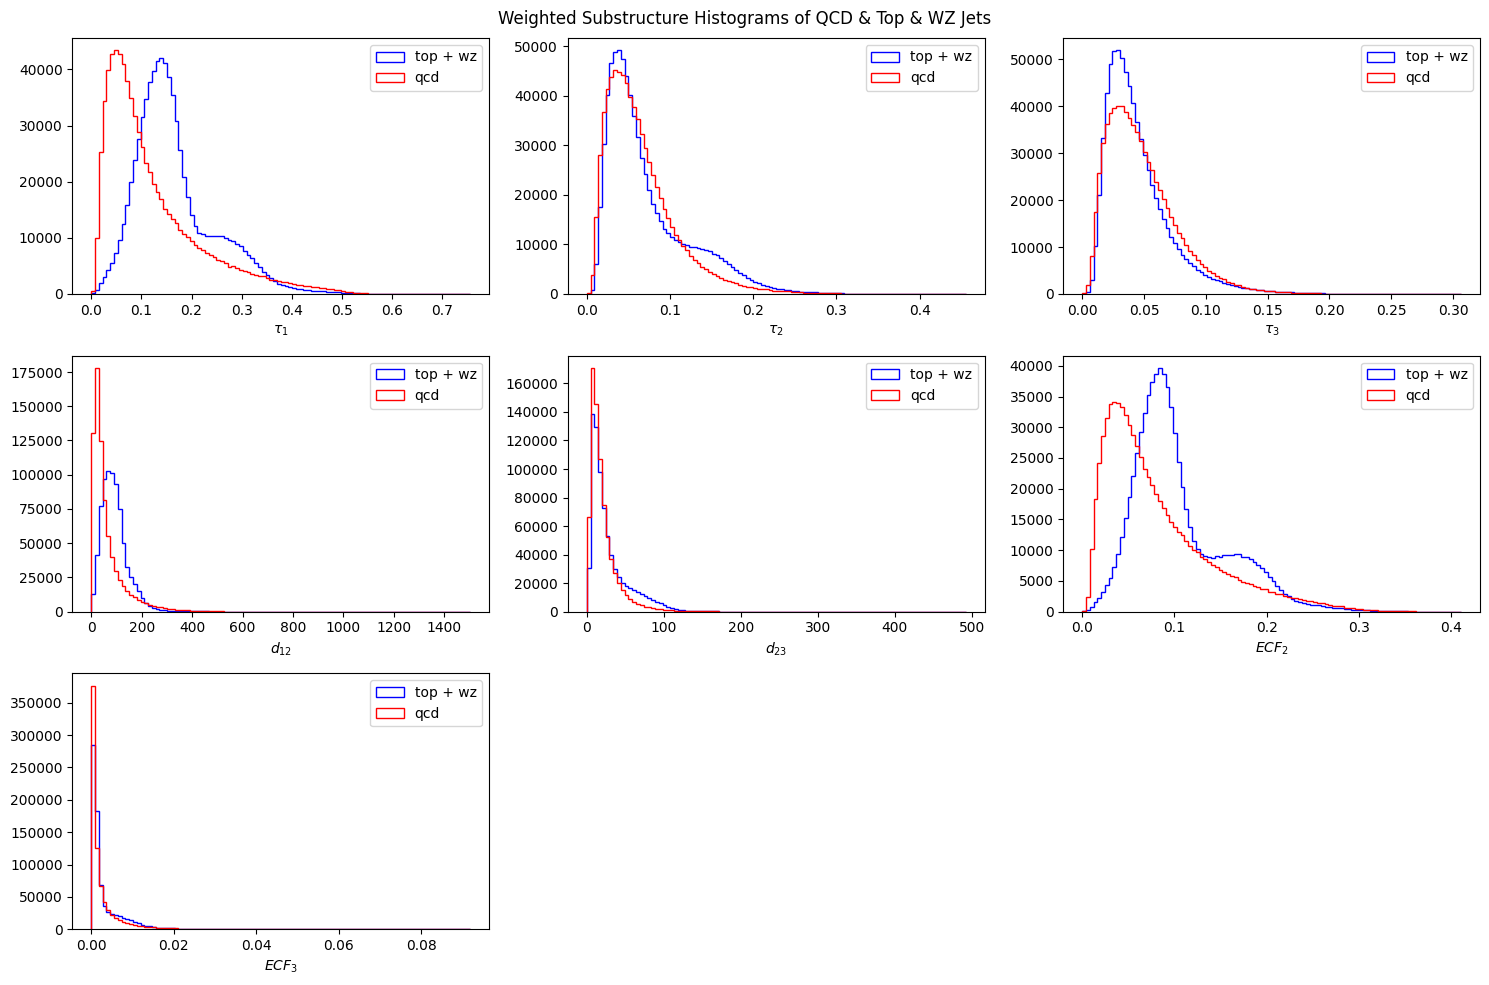

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))  # taller for 3x3 grid
axes = axes.flatten()  # Now axes2[0] ... axes2[8] are valid
labels = ['qcd', 'top + wz']
colors = ['red', 'blue']
n_bins = 100
weight_arrays = [np.full(len(qcd_df), weight_0), np.full(len(signal_df), weight_1)]
features = ['tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3']
xlabels = [r'$\tau_1$', r'$\tau_2$', r'$\tau_3$', r'$d_{12}$', r'$d_{23}$', r'$ECF_2$', r'$ECF_3$']

for i, (feature, xlabel) in enumerate(zip(features, xlabels)):
    axes[i].hist(
        [getattr(qcd_df, feature), getattr(signal_df, feature)],
        bins=n_bins,
        histtype='step',
        color=colors,
        label=labels,
        weights=weight_arrays
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

# Optional: Hide empty axes if you only use 7 out of 9
for ax in axes[7:]:
    ax.axis('off')

fig.suptitle("Weighted Substructure Histograms of QCD & Top & WZ Jets")
plt.tight_layout()
plt.show()

Substructures are very unique!

Now, lets normalize this data with sklearn.preprocessing.StandardScaler()!!!

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# We will need numpy arrays, and we want to fit the scaler to the features, not labels!!!
# Also we will need to fit the scaler to the combined dataset of QCD & Top jets.
combined_np = np.vstack([qcd_np, top_np, wz_np])
combined_labels = np.concatenate([np.zeros(len(qcd_np), dtype=np.float32), np.ones(len(top_np), dtype=np.float32), np.ones(len(wz_np), dtype=np.float32)])

combined_np = np.column_stack([combined_np, combined_labels])

# Create a random number generator with a fixed seed
rng = np.random.default_rng(42)

# Permute the rows
shuffled_np = combined_np[rng.permutation(combined_np.shape[0])]

print(combined_labels.shape)
print(combined_np.shape)
print(shuffled_np[:,:])

(1546865,)
(1546865, 12)
[[ 6.21683346e+02 -1.38998251e-02  1.54847600e+00 ...  1.61196592e-01
   4.65502338e-03  1.00000000e+00]
 [ 5.56378952e+02  1.13671637e+00 -1.29277630e+00 ...  1.82879806e-01
   6.98995221e-03  1.00000000e+00]
 [ 5.83831902e+02  1.20259510e+00 -2.53887375e+00 ...  7.48856622e-02
   9.64062220e-04  1.00000000e+00]
 ...
 [ 5.59090381e+02 -7.01338656e-01  1.04948941e+00 ...  7.41471555e-02
   9.69371336e-04  1.00000000e+00]
 [ 5.00109132e+02  1.59520786e+00  1.45184806e-01 ...  1.54090692e-01
   6.31317994e-03  1.00000000e+00]
 [ 4.69848082e+02 -8.74741665e-01 -1.21427883e+00 ...  1.09247282e-02
   2.48837303e-05  0.00000000e+00]]


In [19]:
# Fit the scaler to only features...
scaled_np = scaler.fit_transform(shuffled_np[:,:-1])

# Transform QCD and Top seperately for the sake of plotting
scaled_qcd = scaler.transform(qcd_np)
scaled_top = scaler.transform(top_np)
scaled_wz = scaler.transform(wz_np)

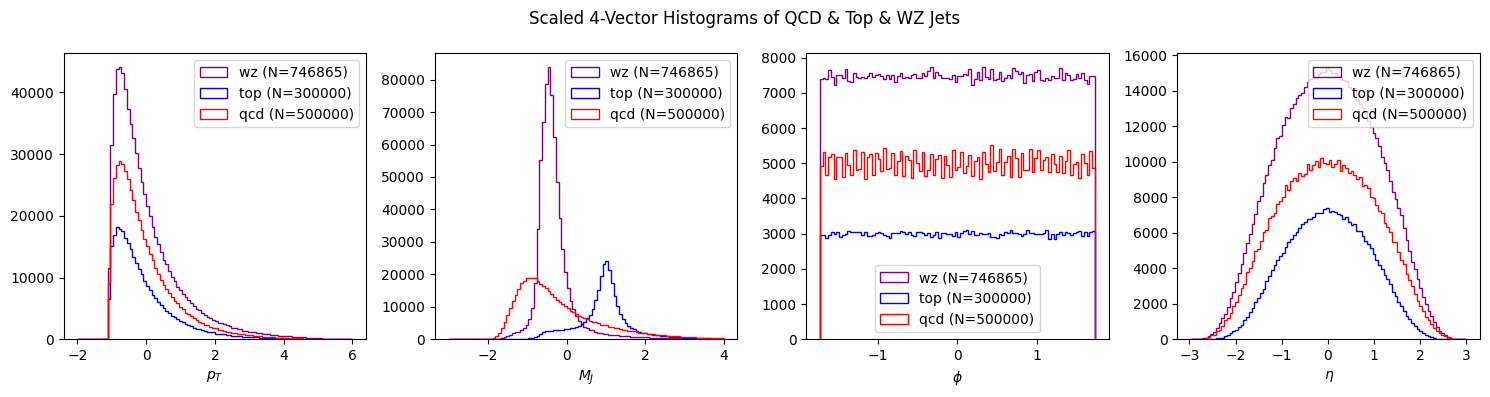

In [20]:
# Plot the scaled results
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Calculate counts, useful to see how weighing affects total counts...
labels = [f'qcd (N={len(scaled_qcd)})', f'top (N={len(scaled_top)})', f'wz (N={len(scaled_wz)})']
colors = ['red', 'blue','purple']
n_bins = 100

# Columns: ['pt', 'eta', 'phi', 'mass', 'tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3']
feature_indices = [0, 3, 2, 1]  # pt, mass, phi, eta
xlabels = [r'$p_T$', r'$M_J$', r'$\phi$', r'$\eta$']
ranges = [[-2, 6],[-3, 4],None,None]

for i, (col_idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_qcd[:, col_idx], scaled_top[:, col_idx], scaled_wz[:, col_idx]],
        bins=n_bins,
        range=ranges[i],
        histtype='step',
        color=colors,
        label=labels
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

fig.suptitle("Scaled 4-Vector Histograms of QCD & Top & WZ Jets")
plt.tight_layout()
plt.show()

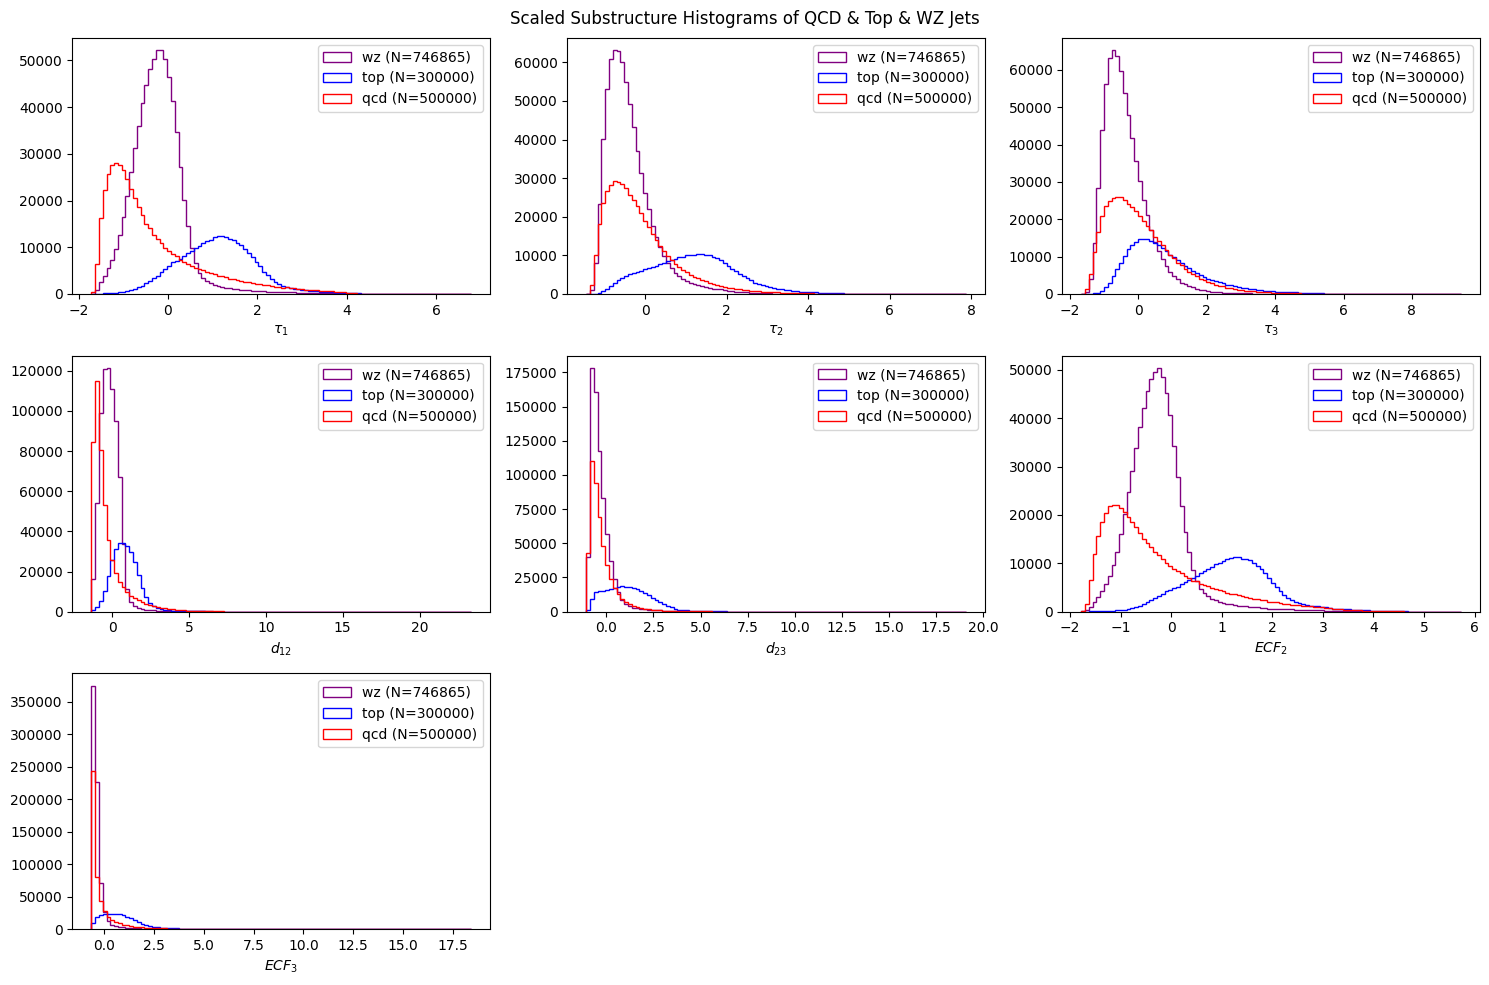

In [21]:
features = ['pt', 'mass', 'phi', 'eta']
feature_indices = [4, 5, 6, 7, 8, 9, 10]  # 'tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3'
xlabels = [r'$\tau_1$', r'$\tau_2$', r'$\tau_3$', r'$d_{12}$', r'$d_{23}$', r'$ECF_2$', r'$ECF_3$']
colors = ['red', 'blue', 'purple']
labels_str = [f'qcd (N={len(scaled_qcd)})', f'top (N={len(scaled_top)})', f'wz (N={len(scaled_wz)})']
n_bins = 100

# === 4. Plot ===
fig, axes = plt.subplots(3, 3, figsize=(15, 10))  # taller for 3x3 grid
axes = axes.flatten()  # Now axes2[0] ... axes2[8] are valid

for i, (idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_qcd[:, idx], scaled_top[:, idx], scaled_wz[:, idx]],
        bins=n_bins,
        histtype='step',
        color=colors,
        label=labels_str,
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

# Optional: Hide empty axes if you only use 7 out of 9
for ax in axes[7:]:
    ax.axis('off')

fig.suptitle("Scaled Substructure Histograms of QCD & Top & WZ Jets")
plt.tight_layout()
plt.show()

Class weights: QCD, Top, WZ = [1.03124333 1.71873889 0.69038135]


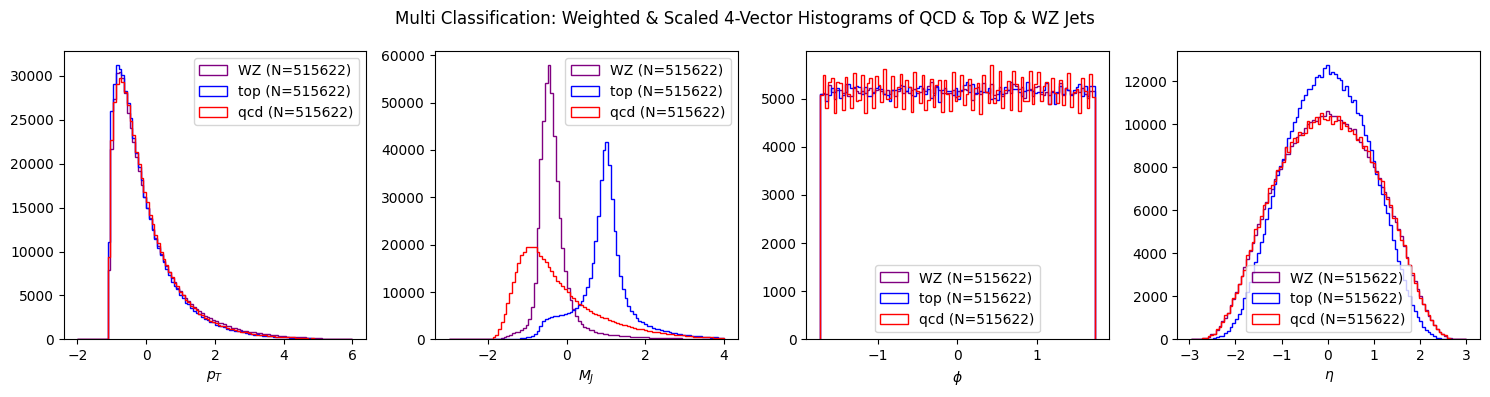

In [22]:
from sklearn.utils.class_weight import compute_class_weight

# === 1. Prepare true labels per jet ===
# Assume QCD = 0, Top = 1, WZ = 2
y_qcd = np.zeros(len(scaled_qcd), dtype=int)
y_top = np.ones(len(scaled_top), dtype=int)
y_wz = np.full(len(scaled_wz), 2, dtype=int)

y_all = np.concatenate([y_qcd, y_top, y_wz])

# === 2. Compute class weights ===
weights_array = compute_class_weight(class_weight='balanced', classes=np.array([0, 1, 2]), y=y_all)
print("Class weights: QCD, Top, WZ =", weights_array)

# === 3. Build per-sample weight arrays ===
weights_qcd = np.full(len(scaled_qcd), weights_array[0])
weights_top = np.full(len(scaled_top), weights_array[1])
weights_wz  = np.full(len(scaled_wz),  weights_array[2])

# Group for plotting
sample_weights = [weights_qcd, weights_top, weights_wz]
features = ['pt', 'mass', 'phi', 'eta']
feature_indices = [0, 3, 2, 1]  # order in scaled_*
xlabels = [r'$p_T$', r'$M_J$', r'$\phi$', r'$\eta$']
colors = ['red', 'blue', 'purple']
labels_str = [
    f'qcd (N={weights_array[0] * len(scaled_qcd):.0f})',
    f'top (N={weights_array[1] * len(scaled_top):.0f})',
    f'WZ (N={weights_array[2] * len(scaled_wz):.0f})'
]
ranges = [[-2, 6], [-3, 4], None, None]
n_bins = 100

# === 4. Plot ===
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, (idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_qcd[:, idx], scaled_top[:, idx], scaled_wz[:, idx]],
        bins=n_bins,
        range=ranges[i],
        histtype='step',
        color=colors,
        label=labels_str,
        weights=sample_weights
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

fig.suptitle("Multi Classification: Weighted & Scaled 4-Vector Histograms of QCD & Top & WZ Jets")
plt.tight_layout()
plt.show()

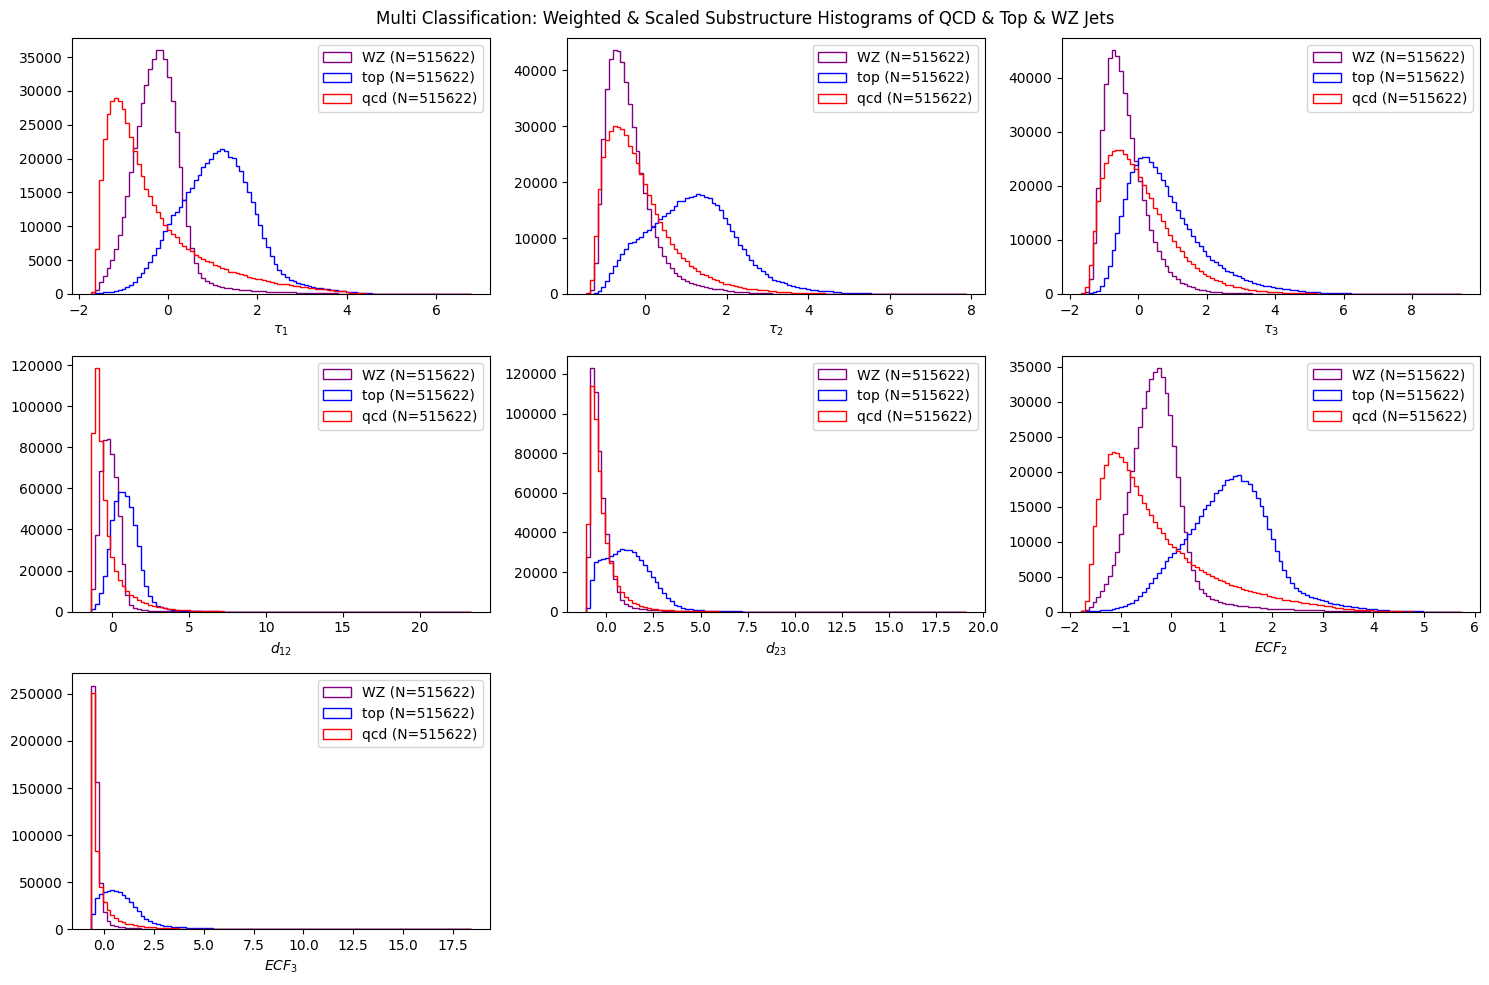

In [23]:

sample_weights = [weights_qcd, weights_top, weights_wz]
features = ['pt', 'mass', 'phi', 'eta']
feature_indices = [4, 5, 6, 7, 8, 9, 10]  # 'tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3'
xlabels = [r'$\tau_1$', r'$\tau_2$', r'$\tau_3$', r'$d_{12}$', r'$d_{23}$', r'$ECF_2$', r'$ECF_3$']
colors = ['red', 'blue', 'purple']
labels_str = [
    f'qcd (N={weights_array[0] * len(scaled_qcd):.0f})',
    f'top (N={weights_array[1] * len(scaled_top):.0f})',
    f'WZ (N={weights_array[2] * len(scaled_wz):.0f})'
]
n_bins = 100

# === 4. Plot ===
fig, axes = plt.subplots(3, 3, figsize=(15, 10))  # taller for 3x3 grid
axes = axes.flatten()  # Now axes2[0] ... axes2[8] are valid

for i, (idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_qcd[:, idx], scaled_top[:, idx], scaled_wz[:, idx]],
        bins=n_bins,
        histtype='step',
        color=colors,
        label=labels_str,
        weights=sample_weights
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

# Optional: Hide empty axes if you only use 7 out of 9
for ax in axes[7:]:
    ax.axis('off')

fig.suptitle("Multi Classification: Weighted & Scaled Substructure Histograms of QCD & Top & WZ Jets")
plt.tight_layout()
plt.show()

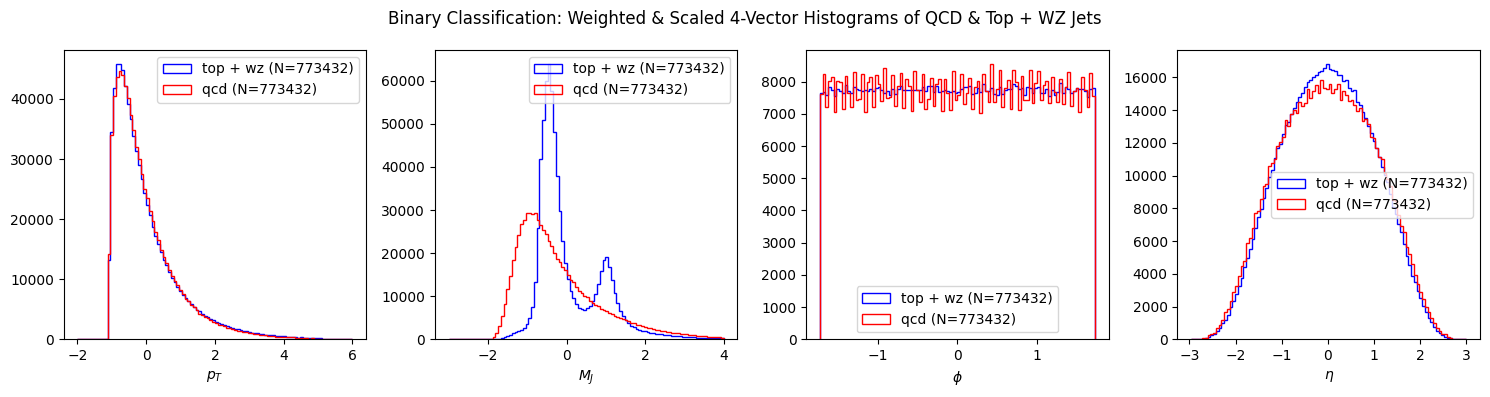

In [24]:
# Visualising for Binary Classification
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
scaled_signal = np.concatenate([scaled_top, scaled_wz])

# Labels and colors
labels = [f'qcd (N={weight_0 * len(scaled_qcd):.0f})', f'top + wz (N={weight_1*(len(scaled_top)+len(scaled_wz)):.0f})']
colors = ['red', 'blue']
n_bins = 100
feature_indices = [0, 3, 2, 1]  # pt, mass, phi, eta
xlabels = [r'$p_T$', r'$M_J$', r'$\phi$', r'$\eta$']
ranges = [[-2, 6], [-3, 4], None, None]

for i, (col_idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_qcd[:, col_idx], scaled_signal[:, col_idx]],
        bins=n_bins,
        range=ranges[i],
        histtype='step',
        color=colors,
        label=labels,
        weights=[
            np.full(len(scaled_qcd), weight_0),
            np.full(len(scaled_signal), weight_1)
        ]
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

fig.suptitle("Binary Classification: Weighted & Scaled 4-Vector Histograms of QCD & Top + WZ Jets")
plt.tight_layout()
plt.show()

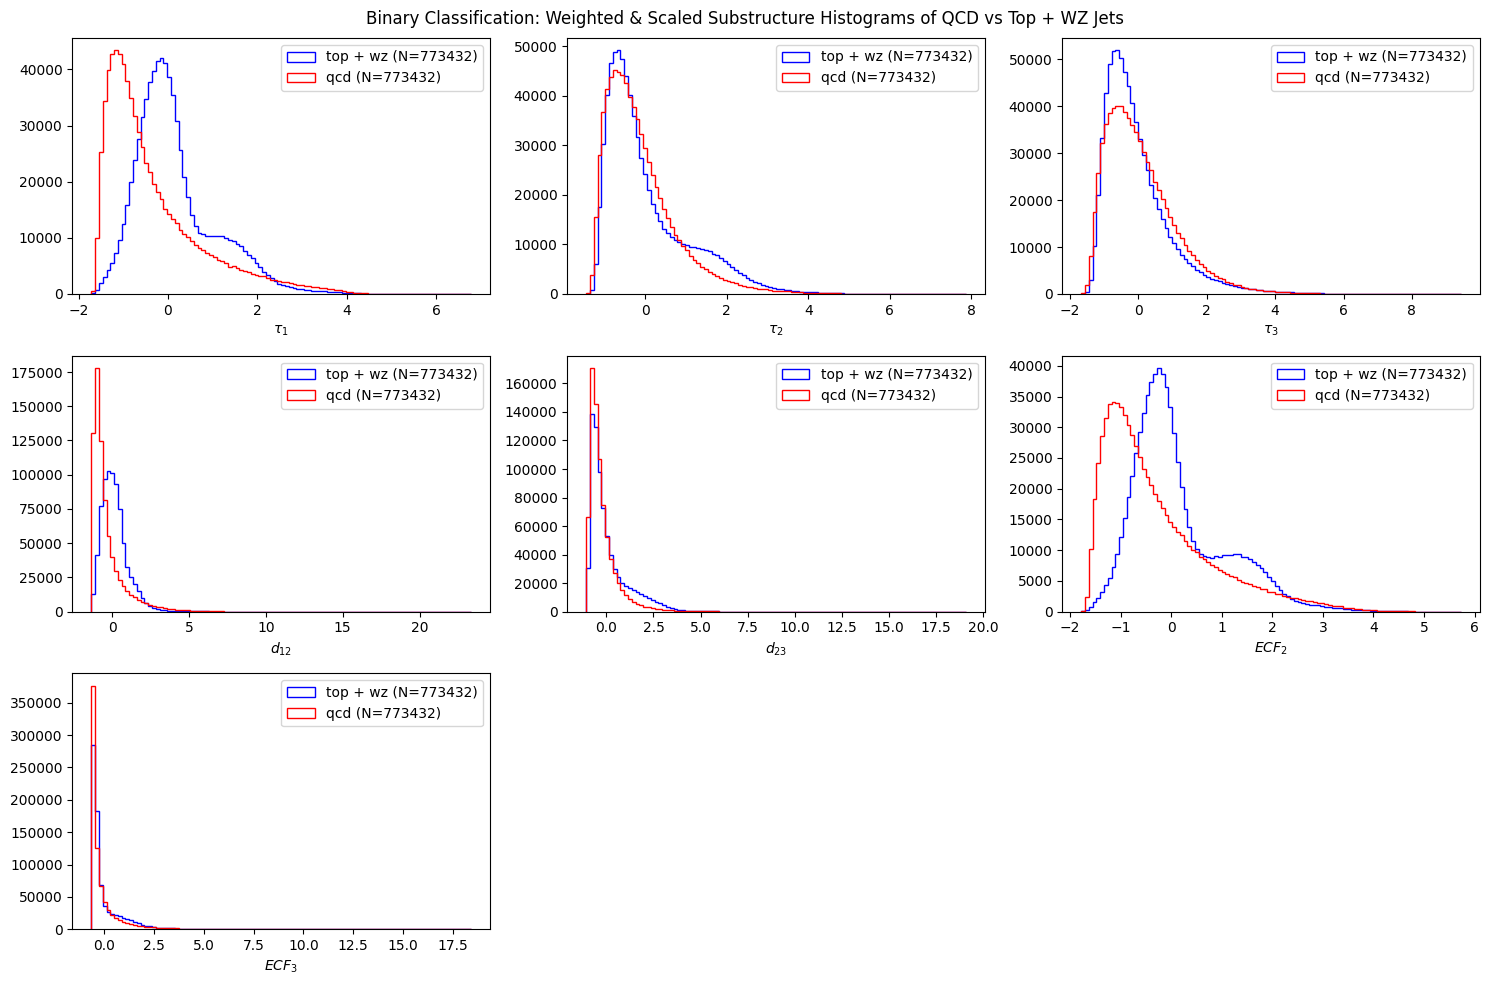

In [25]:
# Prepare binary grouping
scaled_signal = np.concatenate([scaled_top, scaled_wz])
weights_signal = np.full(len(scaled_signal), weight_1)
weights_qcd = np.full(len(scaled_qcd), weight_0)
sample_weights = [weights_qcd, weights_signal]

# Labels and features
labels_str = [
    f'qcd (N={weight_0 * len(scaled_qcd):.0f})',
    f'top + wz (N={weight_1 * len(scaled_signal):.0f})'
]
colors = ['red', 'blue']
feature_indices = [4, 5, 6, 7, 8, 9, 10]  # tau1, tau2, tau3, d12, d23, ECF2, ECF3
xlabels = [r'$\tau_1$', r'$\tau_2$', r'$\tau_3$', r'$d_{12}$', r'$d_{23}$', r'$ECF_2$', r'$ECF_3$']
n_bins = 100

# === Plot substructure histograms (3x3 grid) ===
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_qcd[:, idx], scaled_signal[:, idx]],
        bins=n_bins,
        histtype='step',
        color=colors,
        label=labels_str,
        weights=sample_weights
    )
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

# Hide unused axes (8th and 9th in 3x3 grid)
for ax in axes[len(feature_indices):]:
    ax.axis('off')

fig.suptitle("Binary Classification: Weighted & Scaled Substructure Histograms of QCD vs Top + WZ Jets")
plt.tight_layout()
plt.show()

Perfect — standard scaling and class weighting are a quick way to preprocess data and address class imbalance.

However, one of the project’s goals is to make the model sensitive only to jet substructure and not to jet 4-vector kinematics (like $p_T$, $\eta$, $\phi$, and mass).

A possible approach is to match individual kinematic distributions so the model can’t exploit these variables.

But once kinematic features are reweighted, applying global class weights becomes problematic — doing so would distort already-matched distributions.

One workaround is to duplicate Top jets until their count matches QCD, then match kinematic distributions. This reduces class imbalance while keeping kinematics neutral.

⚠️ However, duplicating data may increase overfitting risk and computational load since it introduces no new variation.

Alternatively, we can discard kinematics during training and train only on the 7 substructure features:
['tau1', 'tau2', 'tau3', 'd12', 'd23', 'ECF2', 'ECF3']. Then apply class weighted training to remove class imbalance from the training process.

✅ This is the most principled approach: the model is blind to kinematics and trained only on substructure without class imbalance.

TL;DR:

But below you can see how we can match the kinematic data for Binary Classification...

In [26]:
# ['pt', 'eta', 'phi', 'mass']
# set range and number of bins, these will work to all of them since they are already normalized.
pt_min = -8
pt_max = 8
n_bins = 100

pt_qcd = np.clip(scaled_qcd[:, 0], pt_min, pt_max)
pt_signal = np.clip(scaled_signal[:, 0], pt_min, pt_max)

eta_qcd = np.clip(scaled_qcd[:, 1], pt_min, pt_max)
eta_signal = np.clip(scaled_signal[:, 1], pt_min, pt_max)

phi_qcd = np.clip(scaled_qcd[:, 2], pt_min, pt_max)
phi_signal = np.clip(scaled_signal[:, 2], pt_min, pt_max)

mass_qcd = np.clip(scaled_qcd[:, 3], pt_min, pt_max)
mass_signal = np.clip(scaled_signal[:, 3], pt_min, pt_max)

# check if any loss to clip, will be important for replacing the p_T column in the combined dataset
print(len(pt_qcd), len(pt_signal))
print(len(eta_qcd), len(eta_signal))
print(len(phi_qcd), len(phi_signal))
print(len(mass_qcd), len(mass_signal))

500000 1046865
500000 1046865
500000 1046865
500000 1046865


In [27]:
# Create an array of equally spaced bin edges for the kinematic histograms
pt_bins = np.linspace(pt_min, pt_max, n_bins)
eta_bins = np.linspace(pt_min, pt_max, n_bins)
phi_bins = np.linspace(pt_min, pt_max, n_bins)
mass_bins = np.linspace(pt_min, pt_max, n_bins)

# Count how many QCD/Top jet falls into each bin
pt_qcd_counts = np.histogram(pt_qcd, pt_bins)[0]
pt_signal_counts = np.histogram(pt_signal, pt_bins)[0]

eta_qcd_counts = np.histogram(eta_qcd, eta_bins)[0]
eta_signal_counts = np.histogram(eta_signal, eta_bins)[0]

phi_qcd_counts = np.histogram(phi_qcd, phi_bins)[0]
phi_signal_counts = np.histogram(phi_signal, phi_bins)[0]

mass_qcd_counts = np.histogram(mass_qcd, mass_bins)[0]
mass_signal_counts = np.histogram(mass_signal, mass_bins)[0]

# Do the division for only valid bins, avoid dividing by 0, assing  0 ratio if cannot divide...
ratio_pt = np.divide(
    pt_qcd_counts,
    pt_signal_counts,
    out=np.zeros_like(pt_qcd_counts, dtype=float),
    where= pt_signal_counts != 0
)

ratio_eta = np.divide(
    eta_qcd_counts,
    eta_signal_counts,
    out=np.zeros_like(eta_qcd_counts, dtype=float),
    where= eta_signal_counts != 0
)

ratio_phi = np.divide(
    phi_qcd_counts,
    phi_signal_counts,
    out=np.zeros_like(phi_qcd_counts, dtype=float),
    where= phi_signal_counts != 0
)

ratio_mass = np.divide(
    mass_qcd_counts,
    mass_signal_counts,
    out=np.zeros_like(mass_qcd_counts, dtype=float),
    where= mass_signal_counts != 0
)

# print(ratio_pt)
# print(ratio_eta)
# print(ratio_phi)
# print(ratio_mass)

In [28]:
def get_weight(sample, i):
    if i == 0:
        pt = sample[:, i]   # Get $p_T$ values for each sample
        bin_idx = np.digitize(pt, pt_bins) - 1  # Assign each $p_T$ to a bin index
        bin_idx = np.clip(bin_idx, 0, len(ratio_pt)-1)  # Clamp index to valid bin range
        return ratio_pt[bin_idx]   # Get the corresponding weight for each sample
    elif i == 1:
        eta = sample[:, i]
        bin_idx = np.digitize(eta, eta_bins) - 1
        bin_idx = np.clip(bin_idx, 0, len(ratio_eta)-1)
        return ratio_eta[bin_idx]
    elif i == 2:
        phi = sample[:, i]
        bin_idx = np.digitize(phi, phi_bins) - 1
        bin_idx = np.clip(bin_idx, 0, len(ratio_phi)-1)
        return ratio_phi[bin_idx]
    elif i == 3:
        mass = sample[:, i]
        bin_idx = np.digitize(mass, mass_bins) - 1
        bin_idx = np.clip(bin_idx, 0, len(ratio_mass)-1)
        return ratio_mass[bin_idx]
    else:
        return None

# assign weight 1 to all QCD, use ratio above for Signal
sample_weight_pt = np.where(shuffled_np[:,-1] == 0, 1, get_weight(scaled_np, 0))
sample_weight_eta = np.where(shuffled_np[:,-1] == 0, 1, get_weight(scaled_np, 1))
sample_weight_phi = np.where(shuffled_np[:,-1] == 0, 1, get_weight(scaled_np, 2))
sample_weight_mass = np.where(shuffled_np[:,-1] == 0, 1, get_weight(scaled_np, 3))

# Ensures the average weight is 1
sample_weight_pt /= sample_weight_pt.mean()
sample_weight_eta /= sample_weight_eta.mean()
sample_weight_phi /= sample_weight_phi.mean()
sample_weight_mass /= sample_weight_mass.mean()

print(sample_weight_pt, len(sample_weight_pt), f'{sample_weight_pt.sum():.0f}')
print(sample_weight_eta, len(sample_weight_eta), f'{sample_weight_eta.sum():.0f}')
print(sample_weight_phi, len(sample_weight_phi), f'{sample_weight_phi.sum():.0f}')
print(sample_weight_mass, len(sample_weight_mass), f'{sample_weight_mass.sum():.0f}')

[0.7653482  0.76362498 0.76804572 ... 0.76362498 0.73394558 1.546865  ] 1546865 1546865
[0.68799924 0.75410097 0.75410097 ... 0.71804278 0.7936682  1.546865  ] 1546865 1546865
[0.72376339 0.73379399 0.74392839 ... 0.73516876 0.75654003 1.546865  ] 1546865 1546865
[0.27251433 0.2908815  0.3017092  ... 0.28637012 0.74465617 1.546865  ] 1546865 1546865


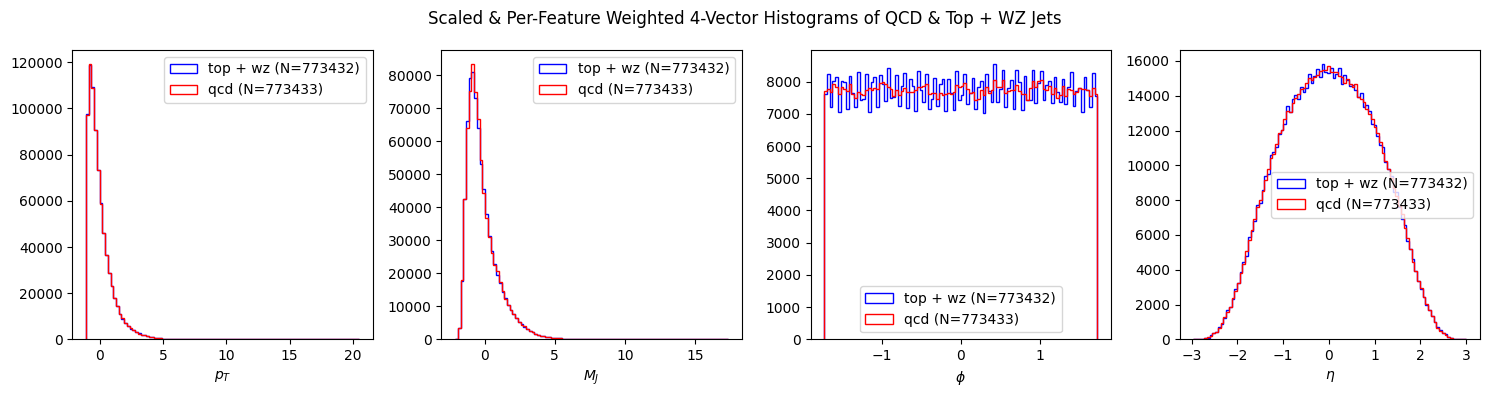

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Masks for QCD and Top
qcd_mask = shuffled_np[:, -1] == 1
signal_mask = shuffled_np[:, -1] == 0

# Label counts (using pt weights just for the title)
labels = [
    f'qcd (N={sample_weight_pt[qcd_mask].sum():.0f})',
    f'top + wz (N={sample_weight_pt[signal_mask].sum():.0f})'
]

colors = ['red', 'blue']
n_bins = 100

features = ['pt', 'eta', 'phi', 'mass']
feature_indices = [0, 3, 2, 1]  # pt, mass, phi, eta
xlabels = [r'$p_T$', r'$M_J$', r'$\phi$', r'$\eta$']

# Dictionary of precomputed weights
sample_weights = {
    'pt': sample_weight_pt,
    'eta': sample_weight_eta,
    'phi': sample_weight_phi,
    'mass': sample_weight_mass
}

for i, (col_idx, xlabel) in enumerate(zip(feature_indices, xlabels)):
    axes[i].hist(
        [scaled_np[qcd_mask, col_idx], scaled_np[signal_mask, col_idx]],
        bins=n_bins,
        histtype='step',
        color=colors,
        label=labels,
        weights=[
            sample_weights[features[col_idx]][qcd_mask],
            sample_weights[features[col_idx]][signal_mask]
        ]
    )
    
    axes[i].legend()
    axes[i].set_xlabel(xlabel)

    # print(i, col_idx, xlabel)
    

fig.suptitle(r'Scaled & Per-Feature Weighted 4-Vector Histograms of QCD & Top + WZ Jets')
plt.tight_layout()
plt.show()

### This structure is exactly what is going on in the jet_tagging/data.py file as the data is prepared for the training ###

### What about constituents? ###

In [30]:
# Read, and save as NDArray.
# Check if cleaning needed.

import h5py
import numpy as np

def load_constituents(path):
    with h5py.File(path, 'r') as f:
        return f["constituents"][:]  # or whatever the dataset key is

qcd_const = load_constituents("data/qcd_const.h5")
top_const = load_constituents("data/top_const.h5")
wz_const  = load_constituents("data/wz_const.h5")

print(qcd_const.shape)
print(top_const.shape)
print(wz_const.shape)


(500000, 20, 4)
(300000, 20, 4)
(746865, 20, 4)


In [31]:
def check_bad_entries(arr, name):
    print(f"{name}:")
    print("  NaNs:", np.isnan(arr).sum())
    print("  +inf:", np.isposinf(arr).sum())
    print("  -inf:", np.isneginf(arr).sum())

check_bad_entries(qcd_const, "QCD")
check_bad_entries(top_const, "Top")
check_bad_entries(wz_const,  "WZ")


QCD:
  NaNs: 0
  +inf: 0
  -inf: 0
Top:
  NaNs: 0
  +inf: 0
  -inf: 0
WZ:
  NaNs: 0
  +inf: 0
  -inf: 0


In [32]:
# lets add the energy info, data augmentation
# (pT,eta,phi,m)

def add_energy(constituents: np.ndarray) -> np.ndarray:
    """
    Adds energy as a fifth feature: E = pT * cosh(η)
    """
    pt = constituents[:, :, 0]
    eta = constituents[:, :, 1]  # Must be uncentered!
    E = pt * np.cosh(eta)
    return np.concatenate([constituents, E[..., None]], axis=-1)


qcd_const_5 = add_energy(qcd_const)
top_const_5 = add_energy(top_const)
wz_const_5 = add_energy(wz_const)

print(qcd_const.shape, qcd_const_5.shape)
print(top_const.shape, top_const_5.shape)
print(wz_const.shape, wz_const_5.shape)

check_bad_entries(qcd_const_5, "QCD")
check_bad_entries(top_const_5, "Top")
check_bad_entries(wz_const_5,  "WZ")

(500000, 20, 4) (500000, 20, 5)
(300000, 20, 4) (300000, 20, 5)
(746865, 20, 4) (746865, 20, 5)
QCD:
  NaNs: 0
  +inf: 0
  -inf: 0
Top:
  NaNs: 0
  +inf: 0
  -inf: 0
WZ:
  NaNs: 0
  +inf: 0
  -inf: 0


In [33]:
# Check Energy Augmentation in more detail

# Function to check energy consistency
def check_energy_consistency(const_data, name=""):
    pt = const_data[:, :, 0]
    eta = const_data[:, :, 1]
    E_manual = pt * np.cosh(eta)
    E_aug = const_data[:, :, -1]

    mean_diff = np.mean(np.abs(E_manual - E_aug))
    max_diff = np.max(np.abs(E_manual - E_aug))

    print(f"{name} Energy Check:")
    print(f"  Mean energy diff: {mean_diff:.6e}")
    print(f"  Max energy diff:  {max_diff:.6e}")
    print()

check_energy_consistency(qcd_const_5, "QCD")
check_energy_consistency(top_const_5, "Top")
check_energy_consistency(wz_const_5, "WZ")

QCD Energy Check:
  Mean energy diff: 0.000000e+00
  Max energy diff:  0.000000e+00

Top Energy Check:
  Mean energy diff: 0.000000e+00
  Max energy diff:  0.000000e+00

WZ Energy Check:
  Mean energy diff: 0.000000e+00
  Max energy diff:  0.000000e+00



In [34]:
# lets load again, extract eta & phis from original small files to center constituent data
def clean_data(data: pd.DataFrame) -> pd.DataFrame:
    data = data.replace([np.inf, -np.inf], np.nan)
    data.dropna(inplace=True)
    return data

qcd_df1 = clean_data(pd.read_hdf("data/qcd_small.h5"))
top_df1 = clean_data(pd.read_hdf("data/top_small.h5"))
wz_df1 = clean_data(pd.read_hdf("data/wz_small.h5"))

qcd_eta = qcd_df1["eta"].to_numpy()
qcd_phi = qcd_df1["phi"].to_numpy()

top_eta = top_df1["eta"].to_numpy()
top_phi = top_df1["phi"].to_numpy()

wz_eta = wz_df1["eta"].to_numpy()
wz_phi = wz_df1["phi"].to_numpy()

In [35]:
def center_constituents(constituents: np.ndarray, jet_eta: np.ndarray, jet_phi: np.ndarray) -> np.ndarray:
    """
    Centers η and ϕ of constituents around their corresponding jet axes.

    Args:
        constituents (np.ndarray): Array of shape (n_jet, n_const, 5) or (n_jet, n_const, 4),
                                   with constituent features including η (index 1) and ϕ (index 2).
        jet_eta (np.ndarray): Array of shape (n_jet,) with η of each jet.
        jet_phi (np.ndarray): Array of shape (n_jet,) with ϕ of each jet.

    Returns:
        np.ndarray: New array with centered η and wrapped Δϕ.
    """
    centered = constituents.copy()

    # Center η
    centered[:, :, 1] = jet_eta[:, np.newaxis] - centered[:, :, 1]

    # Center ϕ with wrap-around at ±π
    dphi = jet_phi[:, np.newaxis] - centered[:, :, 2]
    dphi = np.where(dphi < -np.pi, dphi + 2*np.pi, dphi)
    dphi = np.where(dphi >  np.pi, dphi - 2*np.pi, dphi)
    centered[:, :, 2] = dphi

    return centered

# Apply to each jet class
qcd_const_5c = center_constituents(qcd_const_5, qcd_eta, qcd_phi)
top_const_5c = center_constituents(top_const_5, top_eta, top_phi)
wz_const_5c  = center_constituents(wz_const_5,  wz_eta,  wz_phi)

print(qcd_const_5c.shape)
print(top_const_5c.shape)
print(wz_const_5c.shape)

check_bad_entries(qcd_const_5c, "QCD")
check_bad_entries(top_const_5c, "Top")
check_bad_entries(wz_const_5c,  "WZ")

print(np.min(qcd_const_5c[...,2]),np.max(qcd_const_5c[...,2]))
print(np.min(top_const_5c[...,2]),np.max(top_const_5c[...,2]))
print(np.min(wz_const_5c[...,2]),np.max(wz_const_5c[...,2]))


(500000, 20, 5)
(300000, 20, 5)
(746865, 20, 5)
QCD:
  NaNs: 0
  +inf: 0
  -inf: 0
Top:
  NaNs: 0
  +inf: 0
  -inf: 0
WZ:
  NaNs: 0
  +inf: 0
  -inf: 0
-3.141216446190941 3.1404136075769724
-3.1271216483321944 3.1414327434319977
-3.1415291061330946 3.1404993730679167


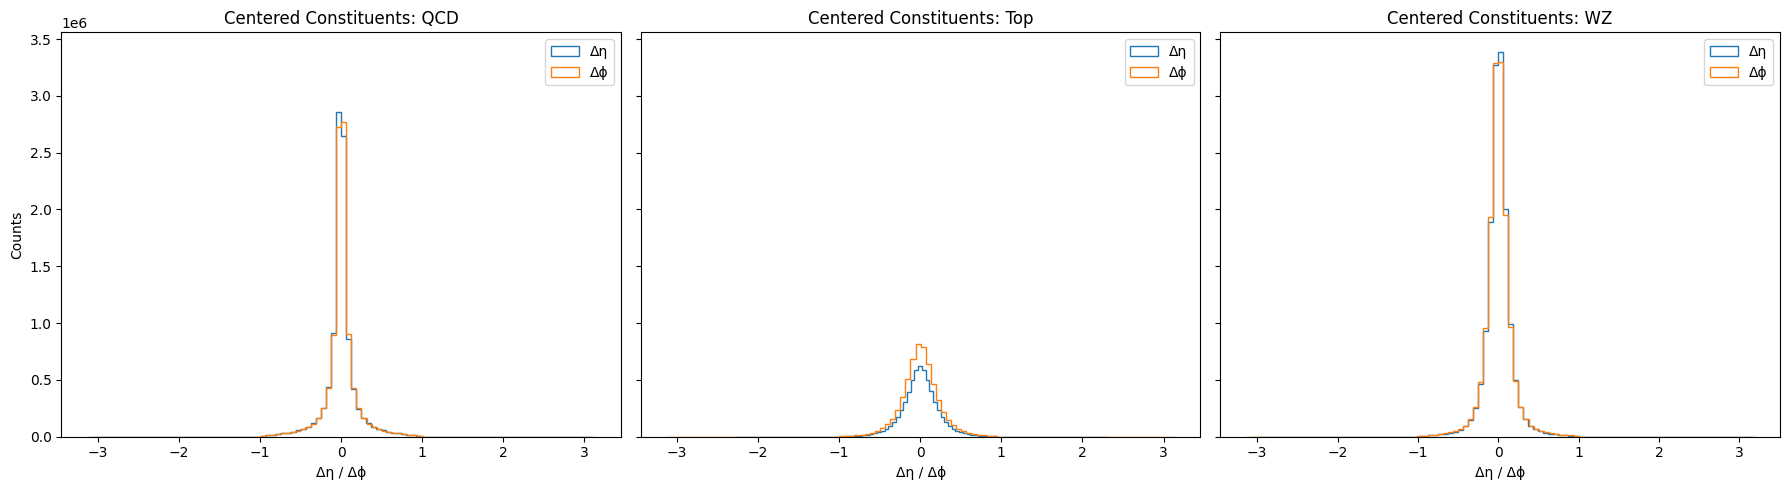

In [36]:
# Well in terms of invalid data and shape checks, energy addition and centering looks good
# Lets be sure that data itself does not look suspicious after the edits

# Well lets do a sanity check centering with histograms

# Helper function to extract flattened Δη and Δϕ arrays
def get_deltas(data):
    delta_eta = data[:, :, 1].flatten()
    delta_phi = data[:, :, 2].flatten()
    return delta_eta, delta_phi

# Extract data
qcd_deta, qcd_dphi = get_deltas(qcd_const_5c)
top_deta, top_dphi = get_deltas(top_const_5c)
wz_deta,  wz_dphi  = get_deltas(wz_const_5c)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
titles = ["QCD", "Top", "WZ"]
deta_list = [qcd_deta, top_deta, wz_deta]
dphi_list = [qcd_dphi, top_dphi, wz_dphi]

for ax, title, deta, dphi in zip(axes, titles, deta_list, dphi_list):
    ax.hist(deta, bins=100, histtype='step', label='Δη')
    ax.hist(dphi, bins=100, histtype='step', label='Δϕ')
    ax.set_title(f"Centered Constituents: {title}")
    ax.set_xlabel("Δη / Δϕ")
    ax.legend()

axes[0].set_ylabel("Counts")
plt.tight_layout()
plt.show()



In [37]:
# Histograms look clean and centered, lets check jet-wise mean of Δη and Δϕ

mean_deta_qcd = np.mean(qcd_const_5c[:, :, 1], axis=1)
mean_dphi_qcd = np.mean(qcd_const_5c[:, :, 2], axis=1)

mean_deta_top = np.mean(top_const_5c[:, :, 1], axis=1)
mean_dphi_top = np.mean(top_const_5c[:, :, 2], axis=1)

mean_deta_wz = np.mean(wz_const_5c[:, :, 1], axis=1)
mean_dphi_wz = np.mean(wz_const_5c[:, :, 2], axis=1)

print("QCD: Mean Δη across jets:", np.mean(mean_deta_qcd))
print("Mean Δϕ across jets:", np.mean(mean_dphi_qcd))

print("Top: Mean Δη across jets:", np.mean(mean_deta_top))
print("Mean Δϕ across jets:", np.mean(mean_dphi_top))

print("WZ: Mean Δη across jets:", np.mean(mean_deta_wz))
print("Mean Δϕ across jets:", np.mean(mean_dphi_wz))

QCD: Mean Δη across jets: -3.092831449567598e-05
Mean Δϕ across jets: 9.585573965888546e-05
Top: Mean Δη across jets: 0.00013403232828762085
Mean Δϕ across jets: 0.0001535073524805718
WZ: Mean Δη across jets: 9.213016810341594e-06
Mean Δϕ across jets: 0.00016337621166183676


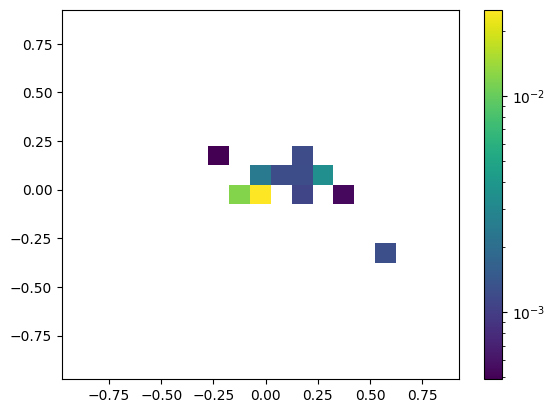

In [38]:
# image of one jet
qc_fracE = qcd_const[:,:,0]*np.cosh(qcd_const[:,:,1])/np.sum(qcd_const[:,:,0]*np.cosh(qcd_const[:,:,1]),axis=1)[::,np.newaxis]

plt.hist2d(qcd_const_5c[...,1][2].ravel(),qcd_const_5c[...,2][2].ravel(),weights=(qc_fracE[2].ravel()/len(qc_fracE[2])),bins=(np.arange(-0.975,0.975,0.1),np.arange(-0.975,0.975,0.1)),norm=matplotlib.colors.LogNorm())
plt.colorbar()
plt.show()

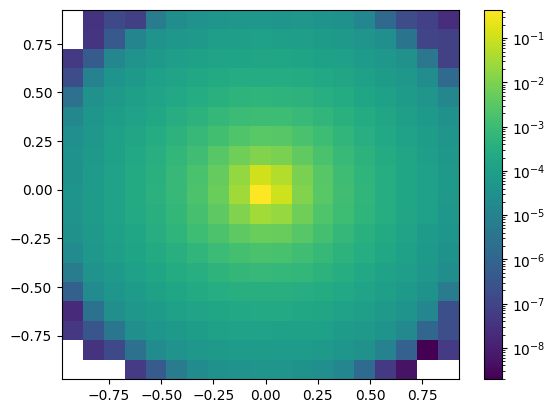

In [39]:
# image of the average jet
plt.hist2d(qcd_const_5c[...,1].ravel(),qcd_const_5c[...,2].ravel(),weights=(qc_fracE.ravel()/len(qc_fracE)),bins=(np.arange(-0.975,0.975,0.1),np.arange(-0.975,0.975,0.1)),norm=matplotlib.colors.LogNorm())
plt.colorbar()
plt.show()

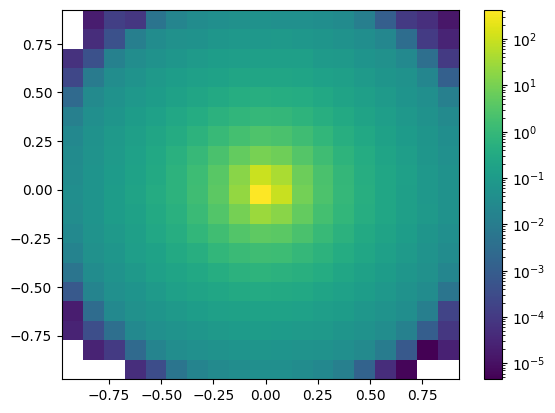

In [40]:
# image of the average jet
plt.hist2d(qcd_const_5c[...,1].ravel(),qcd_const_5c[...,2].ravel(),weights=(qcd_const_5c[...,4].ravel()/len(qcd_const_5c[...,4])),bins=(np.arange(-0.975,0.975,0.1),np.arange(-0.975,0.975,0.1)),norm=matplotlib.colors.LogNorm())
plt.colorbar()
plt.show()

### Perfect, constituent files are explored, data quality checked, augmentations are made and checked ###


### Again, this will be the structure behind the contituent data classes ###